In [1]:
from rdkit import Chem
from rdkit.Chem.rdFMCS import FindMCS
from rdkit import RDLogger
import numpy as np
import csv
import joblib
import sys
import time
from anytree import Node, RenderTree
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step
import helper
from ml_helper import make_fingerprint
import xgboost

In [2]:
clf = joblib.load('models/v12/xg_model.pkl')

In [173]:
# Load the model
clf = xgboost.XGBClassifier()
clf.load_model('models/v14/xg_model.json')

In [174]:
sm_smiles = 'Br.CC1(O)CCCC1'
end_smiles = 'O.CC1(Br)CCCC1'
sm = Chem.MolFromSmiles(sm_smiles)
end = Chem.MolFromSmiles(end_smiles)
sm_node = Node("SM", mol=sm)


In [182]:
# Parameters
force_depth = True
depth_limit = 5
boost = 0
resort_limit = 300
force_correct_last_step = True
# Initialise variables
step_no = 0
product_nodes = []
times_per_layer = []
nodes = [sm_node]
signal_break = False
unique_id = 0
current_max_depth = 0
best_node = None
highest_sim = 0

RDLogger.DisableLog('rdApp.*') 
while step_no < depth_limit:
    product_count = 0
    start_t = time.time()
    print(f'step no {step_no}')
    nodes_to_next = []
    for int in nodes:
        if product_count > resort_limit:
            print(f"Resorting nodes at step {step_no} at depth {current_max_depth}")
            break
        similarity = FindMCS([int.mol, end]).numAtoms
        if hasattr(int, 'priority'):
            p_boost = int.priority + int.depth
        else:
            p_boost = 0
        if hasattr(int, 'product'):
            continue
        try:
            product_mols, mechs, mol_inp  = execute_step("Placeholder", True, False, int.mol, False)
        except Exception as e:
            continue
        for i, product in enumerate(product_mols):
            fp = np.array(make_fingerprint(mol_inp, mechs[i]))
            pred = clf.predict(fp.reshape(1,-1))[0]
            try:
                inchi1 = Chem.MolToInchi(product, options='FixedH')
                inchi2 = Chem.MolToInchi(end, options='FixedH')
            except Exception as e:
                print(f'Error processing product {i}: {e}')
                continue
            if inchi1 == inchi2:
                print('Found the target molecule!')
                print(f'The final step (mol {unique_id}) was predicted: {pred}')
                if force_correct_last_step and pred != 1:
                        continue
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                new_node.priority = -100
                new_node.product = True
                unique_id += 1
                if force_depth and step_no < depth_limit:
                    product_nodes.append(new_node)
                else:  
                    product_nodes.append(new_node)
                    signal_break = True
                break
            elif pred == 1:
                product_count += 1
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                num_MCS = FindMCS([product, end]).numAtoms
                new_node.similarity = num_MCS
                if num_MCS > similarity: # if there is a greater substructure match than the current node
                    new_node.priority = - new_node.depth + num_MCS * boost + p_boost
                    if num_MCS > highest_sim:
                        highest_sim = num_MCS
                        best_node = new_node
                else:
                    new_node.priority = - new_node.depth + p_boost # TODO: consider some decay here
                if new_node.depth > current_max_depth:
                    current_max_depth = new_node.depth
                
                unique_id += 1
        if signal_break:
            break
    if signal_break:
        print("we breaking")
        break
    nodes = sm_node.leaves
    nodes = sorted(nodes, key=lambda x: x.priority)
    step_no += 1
    end_t = time.time()
    times_per_layer.append(end_t - start_t)

print("search is over")

       


step no 0
step no 1
Found the target molecule!
The final step (mol 3) was predicted: 1
step no 2
Found the target molecule!
The final step (mol 5) was predicted: 1
step no 3
Found the target molecule!
The final step (mol 9) was predicted: 1
step no 4
Found the target molecule!
The final step (mol 11) was predicted: 1
search is over


In [183]:
for i, dur in enumerate(times_per_layer):
    print(f'Layer {i+1} took {dur:.2f} seconds')

Layer 1 took 0.24 seconds
Layer 2 took 0.30 seconds
Layer 3 took 0.39 seconds
Layer 4 took 0.32 seconds
Layer 5 took 0.27 seconds


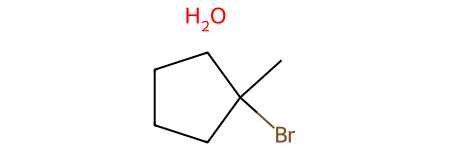

In [184]:
end

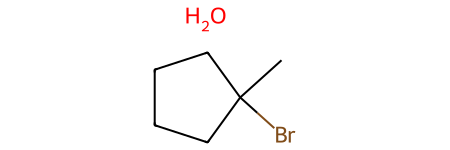

In [185]:
product_nodes[0].mol

In [186]:
def visualise_tree(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(300, 300), legends=[f"Mol {i}" for i in range(len(mols))])

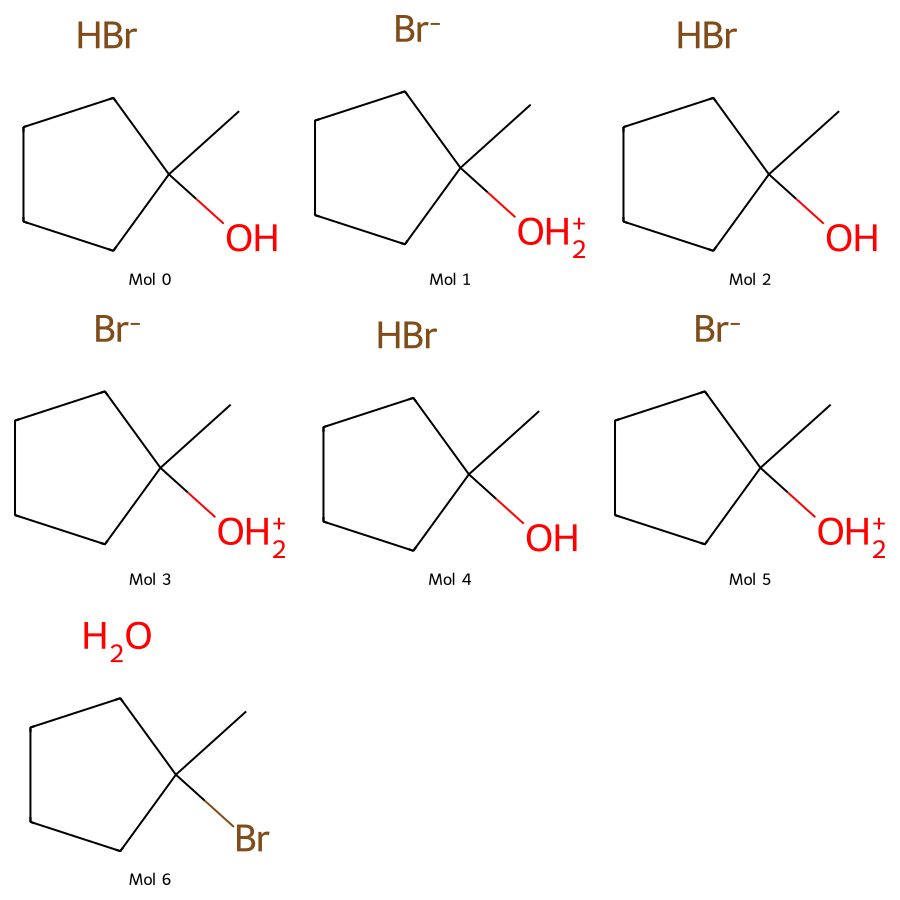

In [189]:
visualise_tree(product_nodes[1])

In [71]:
for pre, fill, node in RenderTree(sm_node):
    print(f"{pre}{node.name} - {Chem.MolToSmiles(node.mol)}")
    #if hasattr(node, 'mech'):
    #    print(f"{pre}Mechanism: {node.mech}")
    #else:
    #    print(f"{pre}Mechanism: None")

SM - O=C(CCCO)CCCO.[OH3+]
├── Mol 0 - [O-]C(=CCCO)CCC[OH2+].[OH3+]
│   ├── Mol 5 - OCCC=C(O)CCCO.[OH3+]
│   │   ├── Mol 41 - O.OCCC=C(O)CCC[OH2+]
│   │   │   ├── Mol 247 - O.OCCC=C([OH2+])CCCO
│   │   │   │   ├── Mol 452 - O.OCCC=C(O)CCC[OH2+]
│   │   │   │   │   ├── Mol 653 - O.OCCC=C([OH2+])CCCO
│   │   │   │   │   ├── Mol 654 - OC(=CCC[OH2+])CCC[OH2+].[OH-]
│   │   │   │   │   ├── Mol 655 - OCCC=C(O)CCCO.[OH3+]
│   │   │   │   │   ├── Mol 656 - C=CCC(O)=CCCO.O.[OH3+]
│   │   │   │   │   └── Mol 657 - O.OCCC[C+](O)CCCO
│   │   │   │   ├── Mol 453 - OCCC=C([OH2+])CCC[OH2+].[OH-]
│   │   │   │   │   ├── Mol 658 - OC(=CCC[OH2+])CCC[OH2+].[OH-]
│   │   │   │   │   ├── Mol 659 - O.OCCC=C([OH2+])CCCO
│   │   │   │   │   ├── Mol 660 - O.O.OCCC=C=CCC[OH2+]
│   │   │   │   │   ├── Mol 661 - O.OCCC=C(O)CCC[OH2+]
│   │   │   │   │   ├── Mol 662 - O.[O-]CCC=C([OH2+])CCC[OH2+]
│   │   │   │   │   ├── Mol 663 - O.[OH-].[OH2+]CCCC1=CCC[OH+]1
│   │   │   │   │   └── Mol 664 - OCCC[C+]([OH2+])CCCO.[O

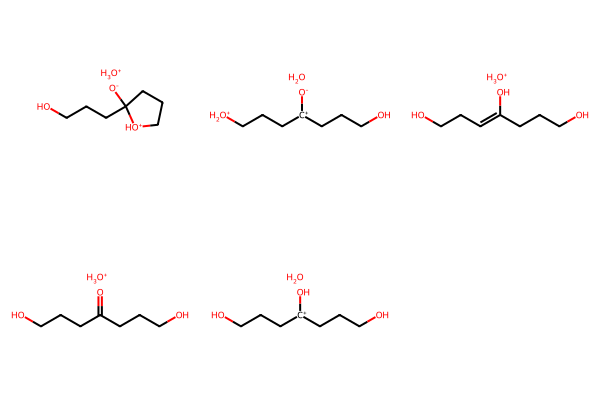

In [72]:
Chem.Draw.MolsToGridImage([m.mol for m in best_node.children])
#best_node.depth

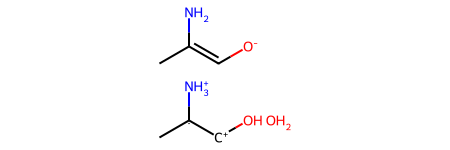

In [120]:
best_node.mol

In [13]:
execute_step('CC1=CCC([C+](C)C)CC1.O', True, False, None, False)

[9, 10, 4, 5, None]
[0, 10, 5, None, None]
[9, 10, 6, 5, None]
[1, 10, 1, None, 2]
[1, 10, 2, None, 1]
[9, 1, 4, 5, None]
[9, 2, 4, 5, None]
[1, 1, 5, 2, None]
[1, 2, 5, 1, None]
[9, 1, 6, 5, None]
[9, 2, 6, 5, None]
[5, 1, 10, 2, None]
[5, 2, 10, 1, None]


([<rdkit.Chem.rdchem.Mol at 0x7f86c92051c0>,
 [[9, 10, 4, 5, None],
  [0, 10, 5, None, None],
  [9, 10, 6, 5, None],
  [1, 10, 1, None, 2],
  [1, 10, 2, None, 1],
  [9, 1, 4, 5, None],
  [9, 2, 4, 5, None],
  [1, 1, 5, 2, None],
  [1, 2, 5, 1, None],
  [9, 1, 6, 5, None],
  [9, 2, 6, 5, None],
  [5, 1, 10, 2, None],
  [5, 2, 10, 1, None]],
 <rdkit.Chem.rdchem.Mol at 0x7f86c9204ba0>)

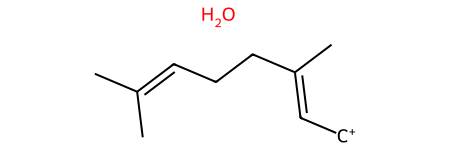

In [14]:
sm

In [15]:
mols, mechs, mol_inp = execute_step('O.CC(C)=CCCC(C)=C[CH2+]', True, False, None, False)

[9, 0, 9, 10, None]
[0, 0, 10, None, None]
[1, 0, 2, None, 4]
[1, 0, 4, None, 2]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 2, 0, 4, None]
[5, 4, 0, 2, None]
[9, 2, 9, 10, None]
[9, 4, 9, 10, None]
[1, 2, 10, 4, None]
[1, 4, 10, 2, None]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 9, 10, None]
[1, 7, 10, 9, None]
[1, 9, 10, 7, None]
[3, 2, 7, 4, 9]
[3, 4, 7, 2, 9]
[3, 2, 9, 4, 7]
[3, 4, 9, 2, 7]
[3, 7, 2, 9, 4]
[3, 9, 2, 7, 4]
[3, 7, 4, 9, 2]
[3, 9, 4, 7, 2]


In [24]:
mols, mechs, mol_inp = execute_step('P', True, False, b, False)

[9, 0, 1, 2, None]
[0, 0, 2, None, None]
[9, 0, 4, 2, None]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 1, 2, None]
[9, 9, 1, 2, None]
[1, 7, 2, 9, None]
[1, 9, 2, 7, None]
[9, 7, 4, 2, None]
[9, 9, 4, 2, None]


In [16]:
for i, mol in enumerate(mols):
    fp = np.array(make_fingerprint(mol_inp, mechs[i]))
    if clf.predict(fp.reshape(1,-1))[0]==1:
        print(f'Predicted product {i} is a valid reaction product')

Predicted product 1 is a valid reaction product
Predicted product 11 is a valid reaction product


In [17]:
b = Chem.Mol(mols[11])

In [18]:
clf.predict(fp.reshape(1,-1))

array([0])

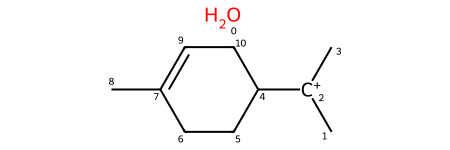

In [23]:
b

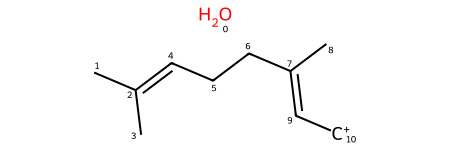

In [22]:
mol_inp

In [21]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

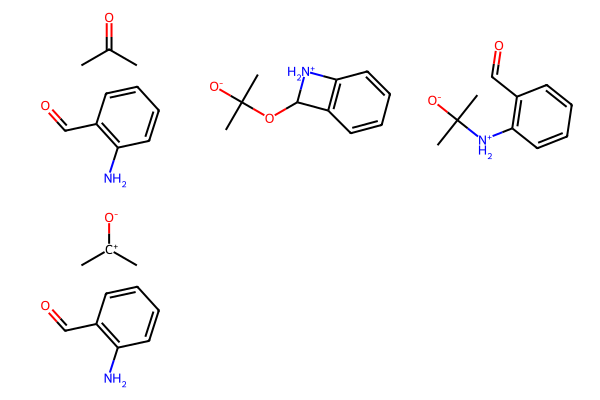

In [29]:
some_mols = [m.mol for m in new_node.parent.children]
Chem.Draw.MolsToGridImage(some_mols)

MCS: [#6]-[#6](:,-[#7]:,-[#6]1:[#6](:[#6]:[#6]:[#6]:[#6]:1):,-[#6]):,-[#6], num atoms: 11, num bonds: 11


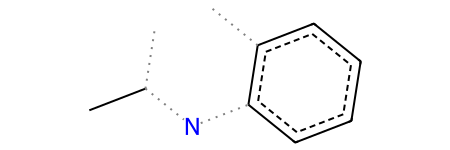

In [40]:
from rdkit.Chem.rdFMCS import FindMCS
result = FindMCS([some_mols[2], end])
print(f'MCS: {result.smartsString}, num atoms: {result.numAtoms}, num bonds: {result.numBonds}')
Chem.MolFromSmarts(result.smartsString)